In [ ]:

#  Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Load the Excel dataset

df = pd.read_excel("EastWestAirlines.xlsx", sheet_name="data")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:

#  Inspect and understand the dataset

# Display dataset structure and data types
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

# Display statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

# Check unique values in Award?
print("\nAWARD COLUMN VALUES")
print(df["Award?"].value_counts().sort_index())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB

MISSING VALUES
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.00,3999.00,3999.00,3999.00,3999.00,3999.00,3999.00,3999.0,3999.00,3999.00,3999.00,3999.00
mean,2014.82,73601.33,144.11,2.06,1.01,1.01,17144.85,11.6,460.06,1.37,4118.56,0.37
std,1160.76,100775.66,773.66,1.38,0.15,0.20,24150.97,9.6,1400.21,3.79,2065.13,0.48
min,1.00,0.00,0.00,1.00,1.00,1.00,0.00,0.0,0.00,0.00,2.00,0.00
25%,1010.50,18527.50,0.00,1.00,1.00,1.00,1250.00,3.0,0.00,0.00,2330.00,0.00
50%,2016.00,43097.00,0.00,1.00,1.00,1.00,7171.00,12.0,0.00,0.00,4096.00,0.00
75%,3020.50,92404.00,0.00,3.00,1.00,1.00,23800.50,17.0,311.00,1.00,5790.50,1.00
max,4021.00,1704838.00,11148.00,5.00,3.00,5.00,263685.00,86.0,30817.00,53.00,8296.00,1.00



AWARD COLUMN VALUES
Award?
0    2518
1    1481
Name: count, dtype: int64


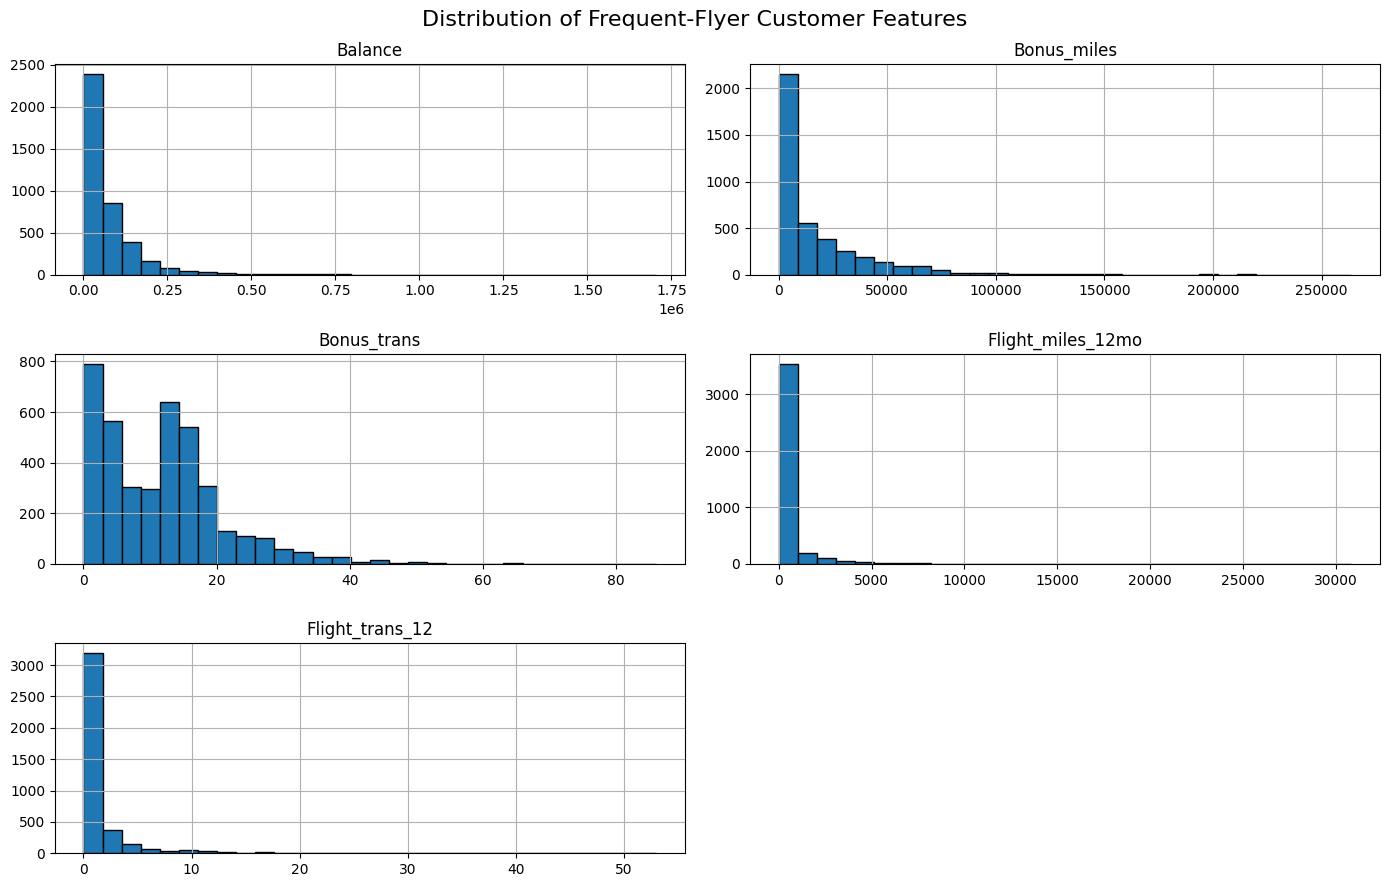

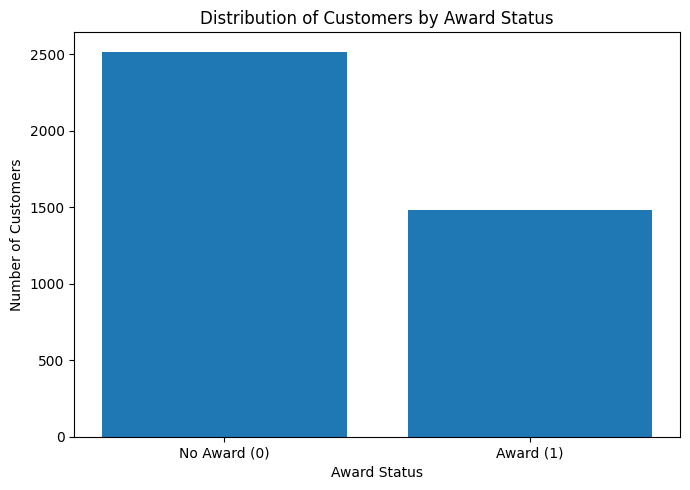

In [ ]:

# Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt

# Select important customer behavior features
features = [
    "Balance",
    "Bonus_miles",
    "Bonus_trans",
    "Flight_miles_12mo",
    "Flight_trans_12"
]

# Plot feature distributions
df[features].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Frequent-Flyer Customer Features",
    fontsize=16
)
plt.tight_layout()
plt.show()

# Visualize award distribution
award_counts = df["Award?"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Award (0)", "Award (1)"],
    [award_counts.get(0, 0), award_counts.get(1, 0)]
)

plt.title("Distribution of Customers by Award Status")
plt.xlabel("Award Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


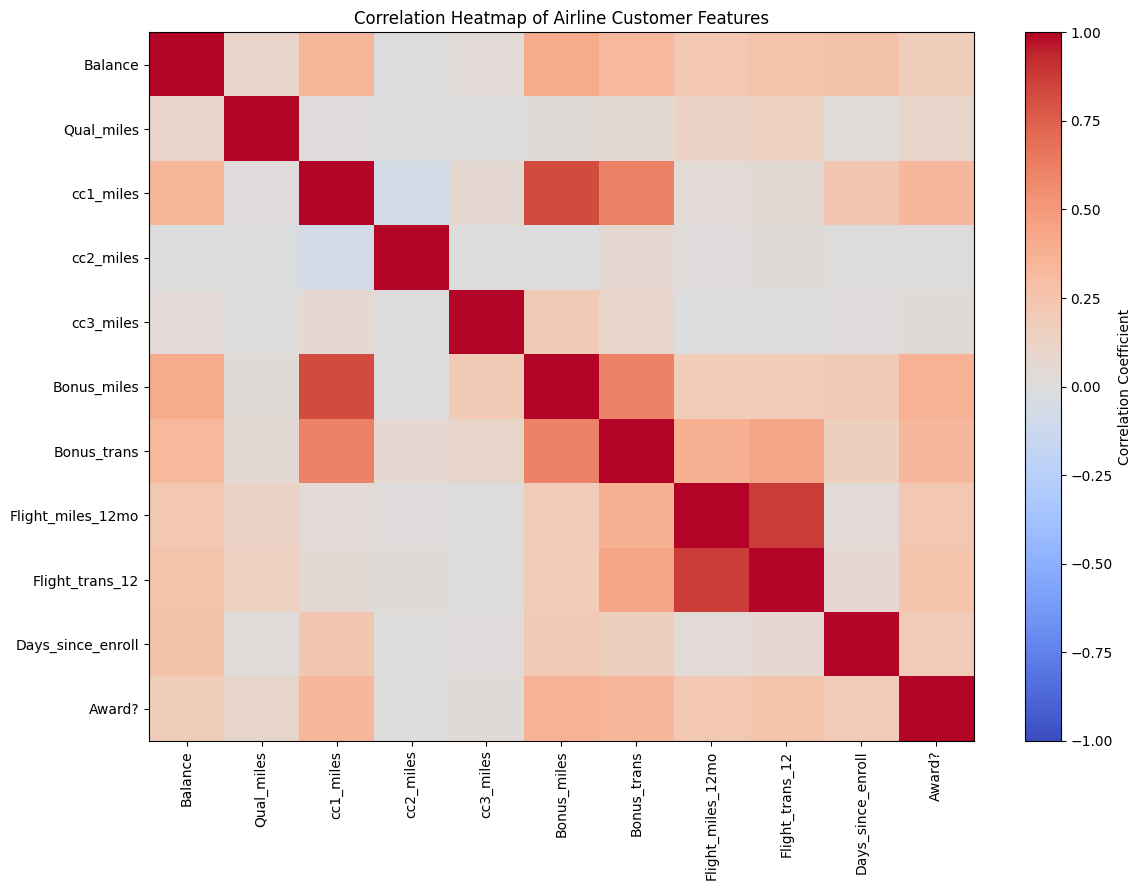

Strongest positive correlations:
Flight_miles_12mo  Flight_trans_12    0.869
cc1_miles          Bonus_miles        0.825
                   Bonus_trans        0.609
Bonus_miles        Bonus_trans        0.603
Bonus_trans        Flight_trans_12    0.432
dtype: float64

Strongest negative correlations:
cc1_miles   cc2_miles   -0.068
Qual_miles  cc2_miles   -0.014
Balance     cc2_miles   -0.009
Qual_miles  cc3_miles   -0.008
cc2_miles   cc3_miles   -0.006
dtype: float64


In [ ]:

# Correlation Analysis

import numpy as np
import matplotlib.pyplot as plt

# Exclude customer ID because it is only an identifier
correlation_data = df.drop(columns=["ID#"])

# Calculate correlations between features
correlation_matrix = correlation_data.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of Airline Customer Features")
plt.tight_layout()
plt.show()

# Display strongest positive and negative correlations
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

print("Strongest positive correlations:")
print(corr_pairs.sort_values(ascending=False).head(5).round(3))

print("\nStrongest negative correlations:")
print(corr_pairs.sort_values().head(5).round(3))


In [ ]:

# Data Preprocessing, Outlier Removal and Feature Scaling

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 1. Create a working copy and exclude the customer identifier
df_clean = df.copy()
feature_cols = [col for col in df.columns if col != "ID#"]

# 2. Handle missing values
imputer = SimpleImputer(strategy="median")
df_clean[feature_cols] = imputer.fit_transform(
    df_clean[feature_cols]
)

# 3. Detect and remove outliers from continuous features
continuous_features = [
    "Balance",
    "Bonus_miles",
    "Bonus_trans",
    "Flight_miles_12mo",
    "Flight_trans_12",
    "Days_since_enroll"
]

outlier_mask = pd.Series(False, index=df_clean.index)

for col in continuous_features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_mask |= (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    )

# Qual_miles has IQR = 0, so use the 99th percentile
# as a separate threshold for unusually high values.
qual_upper = df_clean["Qual_miles"].quantile(0.99)
outlier_mask |= df_clean["Qual_miles"] > qual_upper

print("Rows before outlier removal:", len(df_clean))
print("Rows identified as outliers:", int(outlier_mask.sum()))

# Remove rows identified by the combined rule
df_clean = df_clean.loc[~outlier_mask].copy()

print("Rows after outlier removal:", len(df_clean))
print("Missing values after preprocessing:",
      int(df_clean[feature_cols].isnull().sum().sum()))

# 4. Scale the 11 clustering features
X_clean = df_clean[feature_cols].copy()

scaler_clean = StandardScaler()
X_scaled_clean = scaler_clean.fit_transform(X_clean)

print("Cleaned dataset shape:", df_clean.shape)
print("Scaled feature shape:", X_scaled_clean.shape)


Rows before outlier removal: 3999
Rows identified as outliers: 1003
Rows after outlier removal: 2996
Missing values after preprocessing: 0
Cleaned dataset shape: (2996, 12)
Scaled feature shape: (2996, 11)


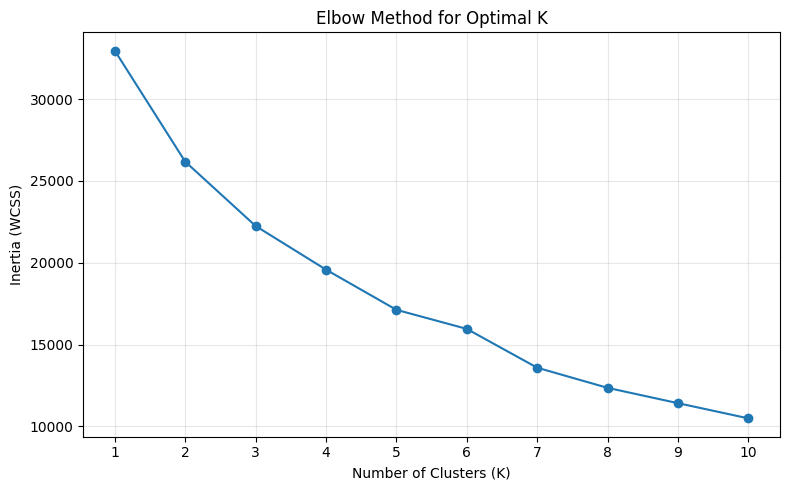

In [ ]:

# Elbow Method for Optimal K

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled_clean)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

#  K-Means Clustering

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled_clean)

kmeans_results = pd.DataFrame({
    "Customer_ID": df_clean["ID#"].values,
    "Cluster": kmeans_labels
})

print("K-Means clustering completed!")
print("Number of clusters:", optimal_k)

print("\nCluster sizes:")
print(kmeans_results["Cluster"].value_counts().sort_index())

kmeans_score = silhouette_score(
    X_scaled_clean,
    kmeans_labels
)

print("\nSilhouette Score:", round(kmeans_score, 4))


K-Means clustering completed!
Number of clusters: 5

Cluster sizes:
Cluster
0    1678
1     912
2     374
3       1
4      31
Name: count, dtype: int64

Silhouette Score: 0.3267


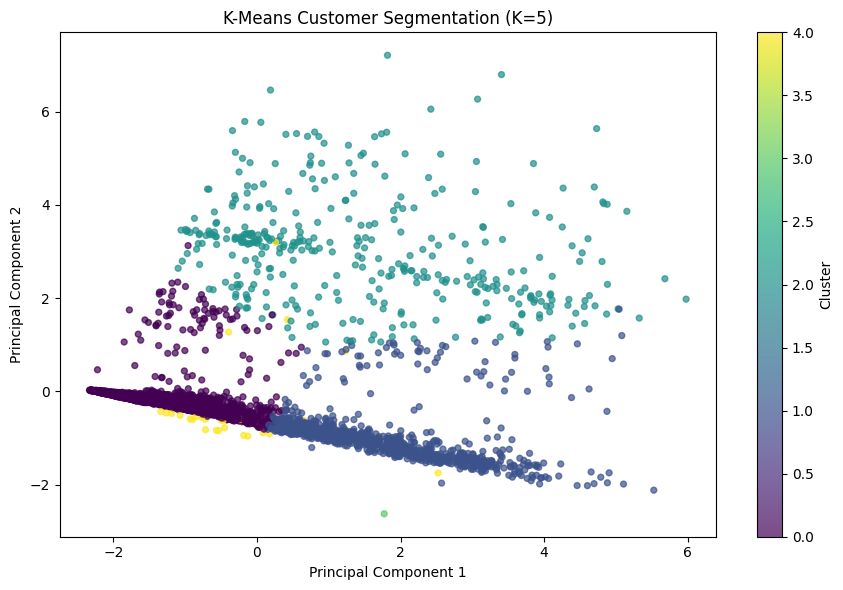

Variance explained by two components: 44.13 %


In [ ]:

# K-Means Cluster Visualization

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_clean)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=18,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segmentation (K=5)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [ ]:

#  K-Means Cluster Profiles

clustered_df = df_clean.copy()
clustered_df["Cluster"] = kmeans_labels

cluster_profile = clustered_df.groupby(
    "Cluster"
).mean(numeric_only=True)

# Customer ID is not a clustering feature
cluster_profile = cluster_profile.drop(
    columns=["ID#"],
    errors="ignore"
)

print("Average Feature Values for Each Cluster:")
display(cluster_profile.round(2))

print("\nCluster Sizes:")
display(
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of Customers")
    .to_frame()
)


Average Feature Values for Each Cluster:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,28923.56,40.38,1.07,1.00,1.0,2680.74,5.31,4.24,0.04,3560.37,0.14
1,73564.79,48.43,3.16,1.00,1.0,24959.37,16.06,7.79,0.06,4544.00,0.49
2,66095.35,125.86,2.00,1.00,1.0,13999.23,11.38,431.18,1.33,4078.03,0.45
3,61474.00,0.00,1.00,1.00,4.0,47717.00,14.00,0.00,0.00,3354.00,0.00
4,41439.32,0.00,1.10,2.35,1.0,12561.97,13.68,24.19,0.16,3870.68,0.23



Cluster Sizes:


,Number of Customers
Cluster,
0,1678
1,912
2,374
3,1
4,31


In [ ]:

#  Hierarchical Clustering using Ward Linkage

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled_clean)

hierarchical_results = pd.DataFrame({
    "Customer_ID": df_clean["ID#"].values,
    "Cluster": hierarchical_labels
})

print("Hierarchical clustering completed!")

print("\nCluster sizes:")
print(
    hierarchical_results["Cluster"]
    .value_counts()
    .sort_index()
)

hierarchical_silhouette = silhouette_score(
    X_scaled_clean,
    hierarchical_labels
)

print("\nHierarchical Silhouette Score:",
      round(hierarchical_silhouette, 4))


Hierarchical clustering completed!

Cluster sizes:
Cluster
0    1088
1    1335
2     467
3      31
4      75
Name: count, dtype: int64

Hierarchical Silhouette Score: 0.2723


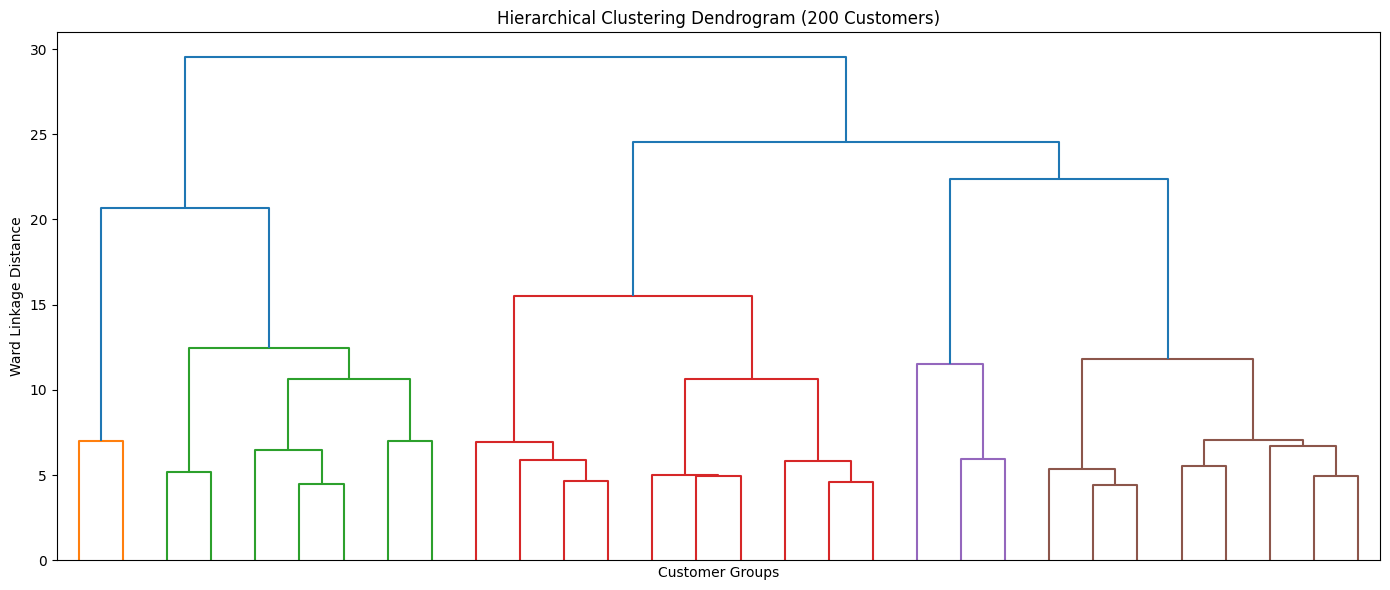

In [ ]:

# Hierarchical Clustering Dendrogram

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

sample_size = min(200, len(X_scaled_clean))
sample_indices = df_clean.sample(
    n=sample_size,
    random_state=42
).index

# Get positions corresponding to the sampled DataFrame indices
sample_positions = df_clean.index.get_indexer(sample_indices)
X_sample = X_scaled_clean[sample_positions]

linkage_matrix = linkage(
    X_sample,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    no_labels=True,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram (200 Customers)")
plt.xlabel("Customer Groups")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


In [ ]:

#  DBSCAN Parameter Tuning

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

tuning_results = []

for eps in [0.8, 1.0, 1.2, 1.5]:
    for min_samples in [5, 10, 15]:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(X_scaled_clean)

        non_noise = labels != -1
        valid_labels = labels[non_noise]
        n_clusters = len(set(labels) - {-1})
        n_noise = int((labels == -1).sum())

        score = np.nan

        if 2 <= len(set(valid_labels)) < len(valid_labels):
            score = silhouette_score(
                X_scaled_clean[non_noise],
                valid_labels,
                sample_size=min(1000, int(non_noise.sum())),
                random_state=42
            )

        tuning_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": n_noise,
            "noise_percent": round(
                n_noise / len(labels) * 100, 2
            ),
            "silhouette": round(score, 4)
            if not np.isnan(score) else np.nan
        })

dbscan_tuning = pd.DataFrame(tuning_results)
display(dbscan_tuning)


,eps,min_samples,clusters,noise_points,noise_percent,silhouette
0,0.8,5,19,682,22.76,0.1598
1,0.8,10,11,898,29.97,0.2129
2,0.8,15,8,1076,35.91,0.2085
3,1.0,5,15,487,16.26,0.1762
4,1.0,10,3,668,22.30,0.3025
5,1.0,15,4,753,25.13,0.2200
6,1.2,5,10,325,10.85,0.2178
7,1.2,10,8,451,15.05,0.2509
8,1.2,15,4,559,18.66,0.2776
9,1.5,5,10,208,6.94,0.2610


In [ ]:

# Final DBSCAN Clustering

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

# Best configuration from the parameter-tuning results
best_eps = 1.0
best_min_samples = 10

dbscan = DBSCAN(
    eps=best_eps,
    min_samples=best_min_samples
)

dbscan_labels = dbscan.fit_predict(X_scaled_clean)

dbscan_results = pd.DataFrame({
    "Customer_ID": df_clean["ID#"].values,
    "Cluster": dbscan_labels
})

n_clusters = len(set(dbscan_labels) - {-1})
noise_count = int(np.sum(dbscan_labels == -1))
noise_percent = noise_count / len(dbscan_labels) * 100

print("DBSCAN clustering completed!")
print("eps:", best_eps)
print("min_samples:", best_min_samples)
print("Clusters excluding noise:", n_clusters)
print("Noise points:", noise_count)
print("Noise percentage:", round(noise_percent, 2), "%")

print("\nCluster sizes:")
print(dbscan_results["Cluster"].value_counts().sort_index())

# Evaluate only non-noise observations
non_noise = dbscan_labels != -1
labels_non_noise = dbscan_labels[non_noise]
X_non_noise = X_scaled_clean[non_noise]

if 2 <= len(set(labels_non_noise)) < len(labels_non_noise):
    dbscan_silhouette = silhouette_score(
        X_non_noise,
        labels_non_noise
    )
    print("\nDBSCAN Silhouette Score:",
          round(dbscan_silhouette, 4))
else:
    dbscan_silhouette = np.nan
    print("\nSilhouette score cannot be calculated.")


DBSCAN clustering completed!
eps: 1.0
min_samples: 10
Clusters excluding noise: 3
Noise points: 668
Noise percentage: 22.3 %

Cluster sizes:
Cluster
-1     668
 0    1733
 1     517
 2      78
Name: count, dtype: int64

DBSCAN Silhouette Score: 0.2976


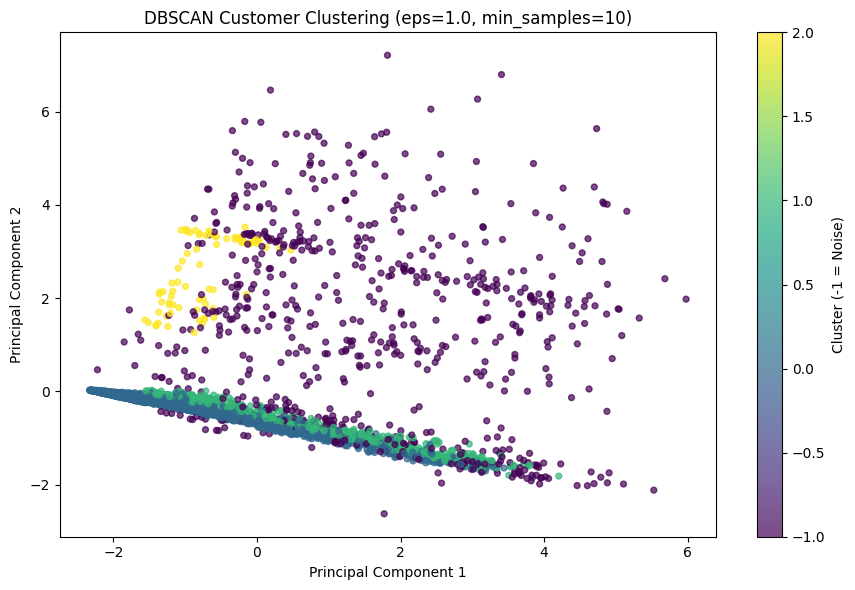

In [ ]:
# DBSCAN Visualization using PCA

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Use the same PCA projection for all observations
pca_dbscan = PCA(n_components=2)
X_pca_dbscan = pca_dbscan.fit_transform(X_scaled_clean)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca_dbscan[:, 0],
    X_pca_dbscan[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=18,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(
    f"DBSCAN Customer Clustering "
    f"(eps={best_eps}, min_samples={best_min_samples})"
)
plt.colorbar(scatter, label="Cluster (-1 = Noise)")
plt.tight_layout()
plt.show()


Final Algorithm Comparison


,Algorithm,Clusters,Silhouette Score,Noise Points
0,K-Means,5,0.3267,0
1,Hierarchical (Ward),5,0.2723,0
2,DBSCAN,3,0.2976,668


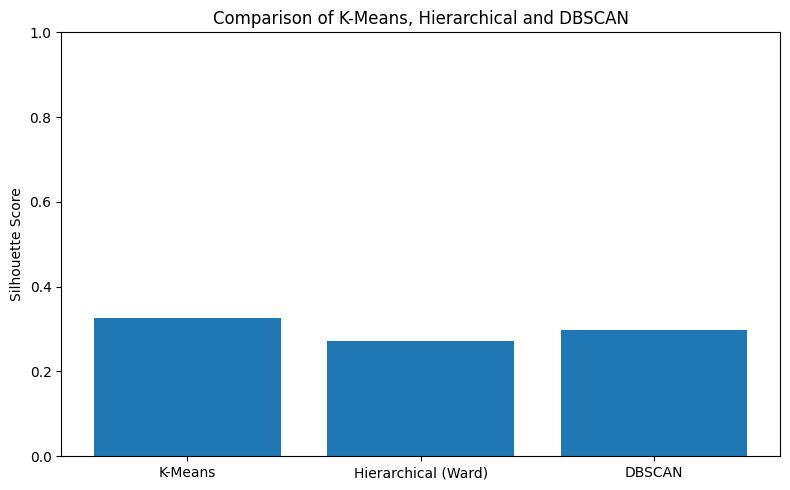

In [ ]:

#  Compare All Three Clustering Algorithms

comparison_df = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical (Ward)",
        "DBSCAN"
    ],
    "Clusters": [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels)),
        n_clusters
    ],
    "Silhouette Score": [
        kmeans_score,
        hierarchical_silhouette,
        dbscan_silhouette
    ],
    "Noise Points": [
        0,
        0,
        noise_count
    ]
})

print("Final Algorithm Comparison")
display(comparison_df.round(4))

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Silhouette Score"]
)

plt.ylabel("Silhouette Score")
plt.title("Comparison of K-Means, Hierarchical and DBSCAN")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [ ]:
#Wine Quality

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

datasets = {
    "Red Wine": red,
    "White Wine": white
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows, {data.shape[1]} columns")
    print("Missing values:", data.isnull().sum().sum())

Red Wine: 1599 rows, 12 columns
Missing values: 0
White Wine: 4898 rows, 12 columns
Missing values: 0


In [7]:
selected = ["alcohol", "volatile acidity", "residual sugar"]

for name, data in datasets.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    stats = pd.DataFrame({
        "Mean": data[selected].mean(),
        "Median": data[selected].median(),
        "Mode": data[selected].mode().iloc[0],
        "Standard Deviation": data[selected].std(),
        "Skewness": data[selected].skew()
    })

    print("\nTask 1(a): Descriptive statistics")
    display(stats.round(4))

    cv = data[selected].std() / data[selected].mean() * 100
    print("\nTask 1(b): Coefficient of variation (%)")
    display(cv.sort_values(ascending=False).round(2).to_frame("CV (%)"))
    print("Greatest relative variability:", cv.idxmax())

    corr = data["alcohol"].corr(data["quality"])
    strength = (
        "weak" if abs(corr) < 0.3 else
        "moderate" if abs(corr) < 0.7 else "strong"
    )
    direction = "positive" if corr > 0 else "negative" if corr < 0 else "no linear"
    print(f"\nTask 1(c): Alcohol-quality Pearson correlation = {corr:.4f}")
    print(f"Interpretation: {direction}, {strength} linear relationship.")


=============== Red Wine ===============

Task 1(a): Descriptive statistics


,Mean,Median,Mode,Standard Deviation,Skewness
alcohol,10.4230,10.20,9.5,1.0657,0.8608
volatile acidity,0.5278,0.52,0.6,0.1791,0.6716
residual sugar,2.5388,2.20,2.0,1.4099,4.5407



Task 1(b): Coefficient of variation (%)


,CV (%)
residual sugar,55.54
volatile acidity,33.92
alcohol,10.22


Greatest relative variability: residual sugar

Task 1(c): Alcohol-quality Pearson correlation = 0.4762
Interpretation: positive, moderate linear relationship.

=============== White Wine ===============

Task 1(a): Descriptive statistics


,Mean,Median,Mode,Standard Deviation,Skewness
alcohol,10.5143,10.40,9.40,1.2306,0.4873
volatile acidity,0.2782,0.26,0.28,0.1008,1.5770
residual sugar,6.3914,5.20,1.20,5.0721,1.0771



Task 1(b): Coefficient of variation (%)


,CV (%)
residual sugar,79.36
volatile acidity,36.23
alcohol,11.70


Greatest relative variability: residual sugar

Task 1(c): Alcohol-quality Pearson correlation = 0.4356
Interpretation: positive, moderate linear relationship.



=============== Red Wine — Task 2 ===============


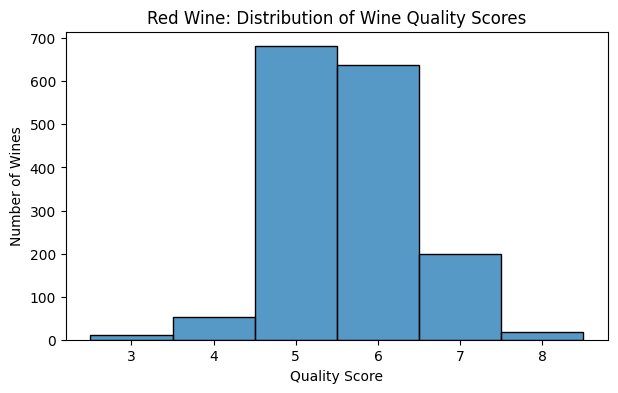

Quality score frequencies:


,Count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


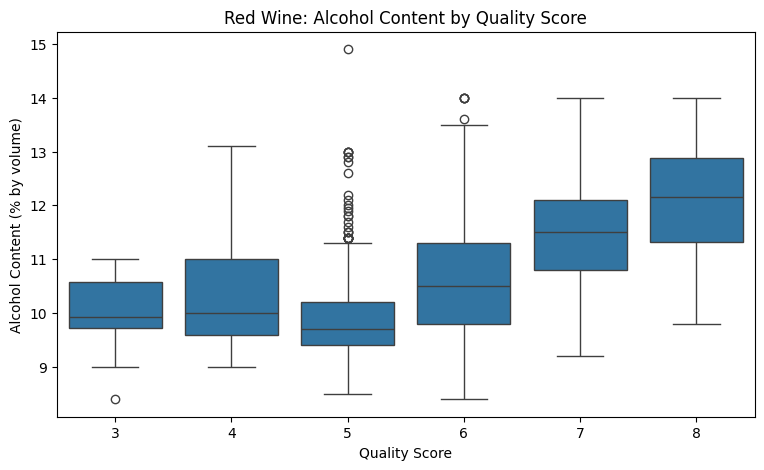

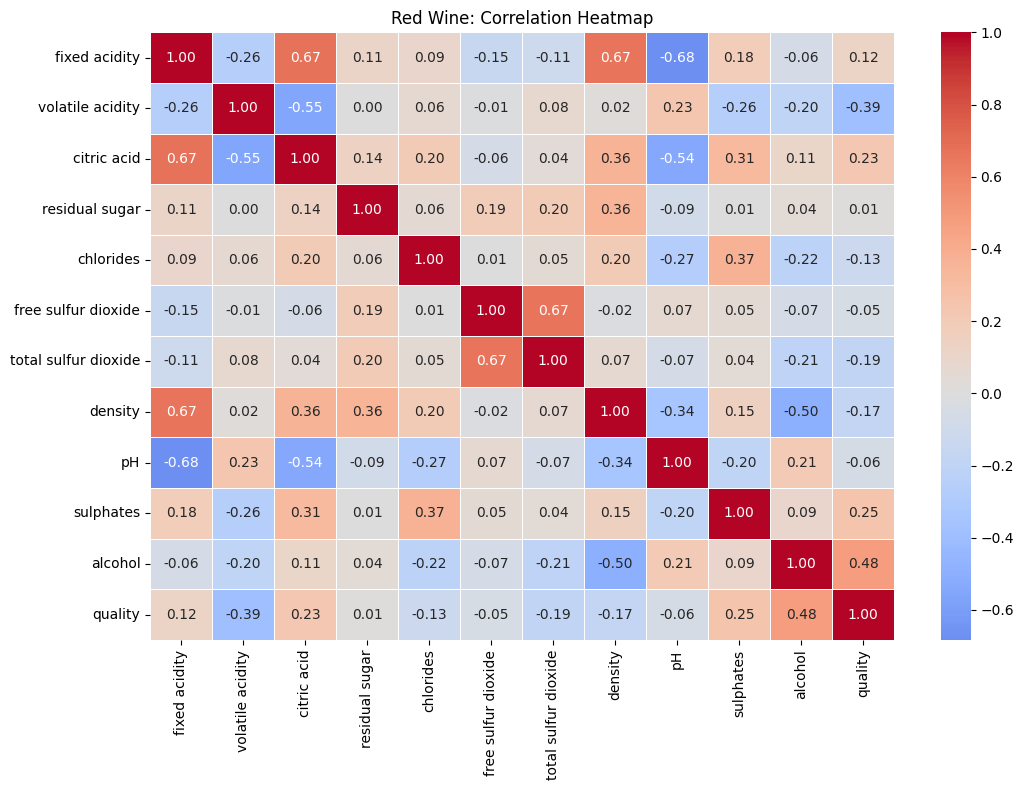

Task 2(d): Two attributes most strongly associated with quality


,Pearson Correlation
alcohol,0.476166
volatile acidity,-0.390558



=============== White Wine — Task 2 ===============


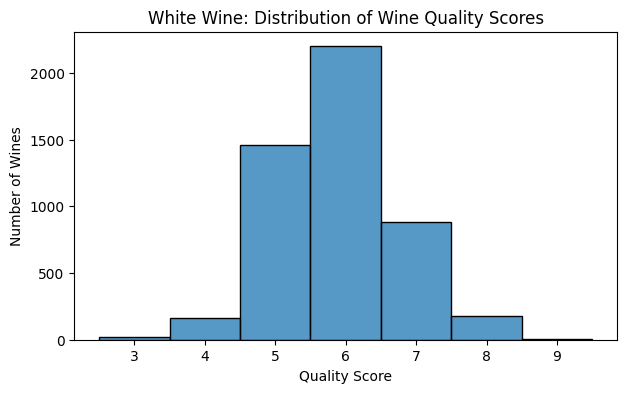

Quality score frequencies:


,Count
quality,
3,20
4,163
5,1457
6,2198
7,880
8,175
9,5


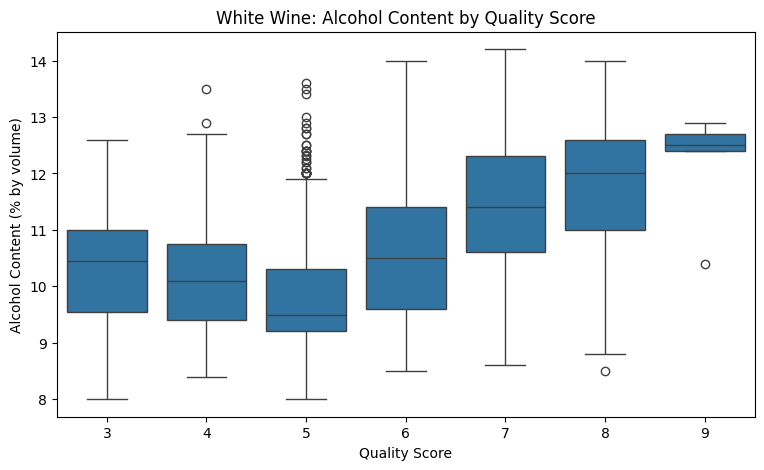

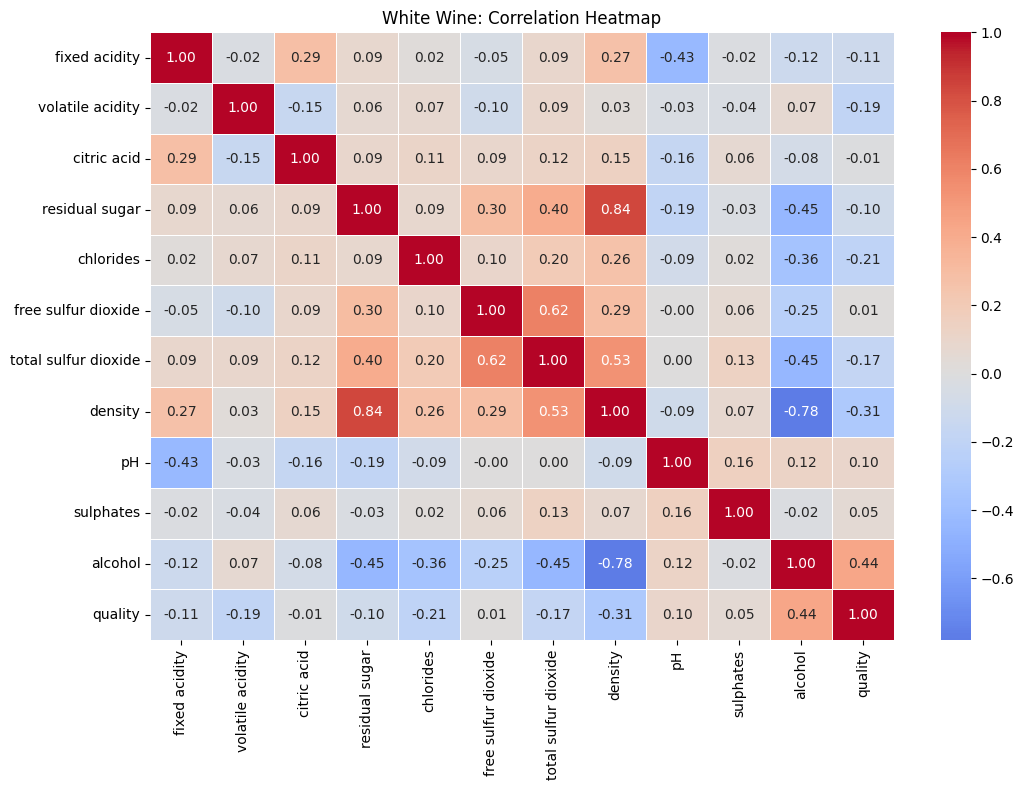

Task 2(d): Two attributes most strongly associated with quality


,Pearson Correlation
alcohol,0.435575
density,-0.307123


In [8]:
for name, data in datasets.items():
    print(f"\n{'=' * 15} {name} — Task 2 {'=' * 15}")

    plt.figure(figsize=(7, 4))
    sns.histplot(data=data, x="quality", discrete=True)
    plt.title(f"{name}: Distribution of Wine Quality Scores")
    plt.xlabel("Quality Score")
    plt.ylabel("Number of Wines")
    plt.show()

    print("Quality score frequencies:")
    display(data["quality"].value_counts().sort_index().to_frame("Count"))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=data, x="quality", y="alcohol")
    plt.title(f"{name}: Alcohol Content by Quality Score")
    plt.xlabel("Quality Score")
    plt.ylabel("Alcohol Content (% by volume)")
    plt.show()

    corr_matrix = data.corr(numeric_only=True)

    plt.figure(figsize=(11, 8))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, linewidths=0.5)
    plt.title(f"{name}: Correlation Heatmap")
    plt.tight_layout()
    plt.show()

    quality_corr = corr_matrix["quality"].drop("quality")
    quality_corr = quality_corr.reindex(
        quality_corr.abs().sort_values(ascending=False).index
    )

    print("Task 2(d): Two attributes most strongly associated with quality")
    display(quality_corr.head(2).to_frame("Pearson Correlation"))


=============== Red Wine — Task 3 ===============
MAE: 0.5035
MSE: 0.39
RMSE: 0.6245
R²: 0.4032

Standardized coefficients, ranked by absolute value:


,Standardized Coefficient
alcohol,0.3678
volatile acidity,-0.2225
sulphates,0.1820
total sulfur dioxide,-0.1488
chlorides,-0.1104
pH,-0.0751
free sulfur dioxide,0.0719
fixed acidity,0.0493
citric acid,-0.0341
density,-0.0238


Two most influential predictors by absolute standardized coefficient:


,Standardized Coefficient
alcohol,0.3678
volatile acidity,-0.2225



Predictor pairs with absolute correlation >= 0.70:
No predictor pairs meet this threshold.


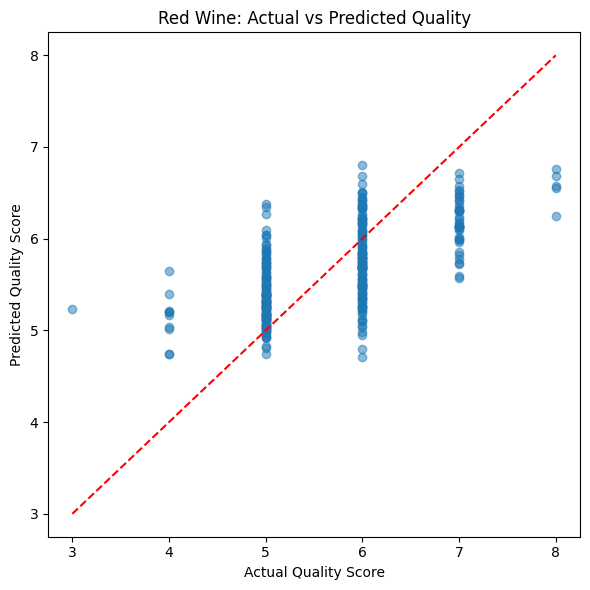


=============== White Wine — Task 3 ===============
MAE: 0.5863
MSE: 0.569
RMSE: 0.7543
R²: 0.2653

Standardized coefficients, ranked by absolute value:


,Standardized Coefficient
density,-0.4234
residual sugar,0.4128
alcohol,0.3171
volatile acidity,-0.2194
pH,0.1017
free sulfur dioxide,0.0963
sulphates,0.0831
fixed acidity,0.0437
total sulfur dioxide,-0.0115
citric acid,-0.0083


Two most influential predictors by absolute standardized coefficient:


,Standardized Coefficient
density,-0.4234
residual sugar,0.4128



Predictor pairs with absolute correlation >= 0.70:


,,Correlation
residual sugar,density,0.838966
density,alcohol,-0.780138


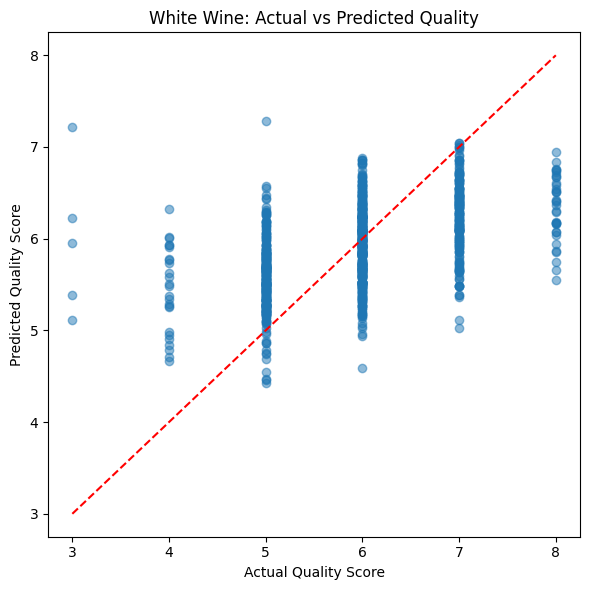

In [9]:
for name, data in datasets.items():
    print(f"\n{'=' * 15} {name} — Task 3 {'=' * 15}")

    X = data.drop(columns="quality")
    y = data["quality"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mse = mean_squared_error(y_test, predictions)
    print("MAE:", round(mean_absolute_error(y_test, predictions), 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(np.sqrt(mse), 4))
    print("R²:", round(r2_score(y_test, predictions), 4))

    # Standardized regression coefficients
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    y_train_scaled = scaler_y.fit_transform(
        y_train.to_numpy().reshape(-1, 1)
    ).ravel()

    standardized_model = LinearRegression()
    standardized_model.fit(X_train_scaled, y_train_scaled)

    coefficients = pd.Series(
        standardized_model.coef_, index=X.columns
    )
    coefficients = coefficients.reindex(
        coefficients.abs().sort_values(ascending=False).index
    )

    print("\nStandardized coefficients, ranked by absolute value:")
    display(coefficients.to_frame("Standardized Coefficient").round(4))

    print("Two most influential predictors by absolute standardized coefficient:")
    display(coefficients.head(2).to_frame("Standardized Coefficient").round(4))

    # Check predictor correlations for possible multicollinearity
    predictor_corr = X.corr()
    upper = predictor_corr.where(
        np.triu(np.ones(predictor_corr.shape), k=1).astype(bool)
    )
    high_corr = upper.stack().loc[lambda s: s.abs() >= 0.70]

    print("\nPredictor pairs with absolute correlation >= 0.70:")
    if high_corr.empty:
        print("No predictor pairs meet this threshold.")
    else:
        display(high_corr.rename("Correlation").to_frame())

    # Actual vs predicted
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, predictions, alpha=0.5)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    plt.plot([low, high], [low, high], "r--")
    plt.title(f"{name}: Actual vs Predicted Quality")
    plt.xlabel("Actual Quality Score")
    plt.ylabel("Predicted Quality Score")
    plt.tight_layout()
    plt.show()